In [1]:
import os

from databricks.connect import DatabricksSession
from databricks.sdk.core import Config

profile = os.getenv("DATABRICKS_CONFIG_PROFILE", "DEV")
config = Config(profile=profile)

print("Databricks Connect Profile:", profile)
print("Databricks Host:", config.host)
print("Databricks Auth Type:", config.auth_type)
print("Config File:", os.path.expanduser(os.getenv("DATABRICKS_CONFIG_FILE", "~/.databrickscfg")))

spark = DatabricksSession.builder.profile(profile).serverless(True).getOrCreate()

print("Spark Version:", spark.version)
print("Session Module:", type(spark).__module__)

Databricks Connect Profile: DEV
Databricks Host: https://dbc-ec87ef87-9aad.cloud.databricks.com
Databricks Auth Type: pat
Config File: C:\Users\Lenovo/.databrickscfg


Spark Version: 4.2.0
Session Module: pyspark.sql.connect.session


In [2]:
try:
    display
except NameError:
    from IPython.display import display as _ipython_display

    def display(value):
        return _ipython_display(value.toPandas() if hasattr(value, "toPandas") else value)

CATALOG = os.getenv("WINE_CATALOG", "workspace")
SCHEMA = os.getenv("WINE_SCHEMA", "wine_eda")
VOLUME = "raw"

VOLUME_DIR = f"/Volumes/{CATALOG}/{SCHEMA}/{VOLUME}/winemag"
RAW_TABLE = f"{CATALOG}.{SCHEMA}.wine_reviews_raw"
CLEAN_TABLE = f"{CATALOG}.{SCHEMA}.wine_reviews_clean"
SAMPLE_TABLE = f"{CATALOG}.{SCHEMA}.wine_reviews_sample"

print("Volume dir  :", VOLUME_DIR)
print("Raw table   :", RAW_TABLE)
print("Clean table :", CLEAN_TABLE)
print("Sample table:", SAMPLE_TABLE)

Volume dir  : /Volumes/workspace/wine_eda/raw/winemag
Raw table   : workspace.wine_eda.wine_reviews_raw
Clean table : workspace.wine_eda.wine_reviews_clean
Sample table: workspace.wine_eda.wine_reviews_sample


In [3]:
for stmt in (
    f"CREATE CATALOG IF NOT EXISTS {CATALOG}",
    f"CREATE SCHEMA IF NOT EXISTS {CATALOG}.{SCHEMA}",
    f"CREATE VOLUME IF NOT EXISTS {CATALOG}.{SCHEMA}.{VOLUME}",
):
    try:
        spark.sql(stmt)
        print("OK   :", stmt)
    except Exception as exc:
        print("SKIP :", stmt, "->", exc)

spark.sql(f"SHOW VOLUMES IN {CATALOG}.{SCHEMA}").show(truncate=False)

OK   : CREATE CATALOG IF NOT EXISTS workspace


OK   : CREATE SCHEMA IF NOT EXISTS workspace.wine_eda


OK   : CREATE VOLUME IF NOT EXISTS workspace.wine_eda.raw


+--------+-----------+
|database|volume_name|
+--------+-----------+
|wine_eda|raw        |
+--------+-----------+



In [4]:
import shutil
import tempfile
import time
import urllib.request
from pathlib import Path

import pandas as pd
from databricks.sdk import WorkspaceClient

w = WorkspaceClient(config=config)

SOURCES = {
    "winemag-data-130k-v2.csv": [
        "https://raw.githubusercontent.com/morisasy/kaggle/master/data/winemag-data-130k-v2.csv",
    ],
    "winemag-data_first150k.csv": [
        "https://raw.githubusercontent.com/stoltzmaniac/wine-reviews-kaggle/master/winemag-data_first150k.csv",
        "https://github.com/stoltzmaniac/wine-reviews-kaggle/raw/master/winemag-data_first150k.csv",
    ],
}


def download(urls, target):
    for url in urls:
        for attempt in range(3):
            try:
                request = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
                with urllib.request.urlopen(request, timeout=180) as response, open(target, "wb") as out:
                    shutil.copyfileobj(response, out)
                return
            except Exception:
                time.sleep(5)
    raise RuntimeError(f"下载失败: {urls}")


def existing_volume_files(directory):
    try:
        return {Path(entry.path).name for entry in w.files.list_directory_contents(directory)}
    except Exception:
        return set()


already = existing_volume_files(VOLUME_DIR)
print("Volume 中已存在:", sorted(already) or "(空)")

with tempfile.TemporaryDirectory(prefix="winemag_") as tmpdir:
    for filename, urls in SOURCES.items():
        remote_path = f"{VOLUME_DIR}/{filename}"
        if filename in already:
            print(f"[skip] 已在 Volume 中: {remote_path}")
            continue
        raw_path = Path(tmpdir) / f"raw_{filename}"
        local_path = Path(tmpdir) / filename
        print(f"[download] {filename}")
        download(urls, raw_path)
        pd.read_csv(raw_path).to_csv(local_path, index=False)
        print(f"[upload]   {local_path.name} -> {remote_path} "
              f"({local_path.stat().st_size / 1e6:.1f} MB)")
        w.files.upload_from(remote_path, str(local_path), overwrite=True)

print("临时目录已清理，本地不保留数据文件")
print("Volume 内容:", sorted(existing_volume_files(VOLUME_DIR)))

Volume 中已存在: ['winemag-data-130k-v2.csv', 'winemag-data_first150k.csv']
[skip] 已在 Volume 中: /Volumes/workspace/wine_eda/raw/winemag/winemag-data-130k-v2.csv
[skip] 已在 Volume 中: /Volumes/workspace/wine_eda/raw/winemag/winemag-data_first150k.csv
临时目录已清理，本地不保留数据文件


Volume 内容: ['winemag-data-130k-v2.csv', 'winemag-data_first150k.csv']


In [5]:
df1 = spark.read.csv(f"{VOLUME_DIR}/winemag-data-130k-v2.csv", header=True, inferSchema=True, multiLine=True)
df2 = spark.read.csv(f"{VOLUME_DIR}/winemag-data_first150k.csv", header=True, inferSchema=True, multiLine=True)

print(f"spark DataFrame type: {type(df1)}")
pdf1 = df1.limit(5).toPandas()
print(f"pandas DataFrame type: {type(pdf1)}")
print(f"df1 columns: {df1.columns}")
print(f"df2 columns: {df2.columns}")

extra_columns = [c for c in df1.columns if c not in set(df2.columns)]
print(f"These columns will be dropped: {extra_columns}")

display(df1.limit(2))

spark DataFrame type: <class 'pyspark.sql.connect.dataframe.DataFrame'>


pandas DataFrame type: <class 'pandas.core.frame.DataFrame'>


df1 columns: ['Unnamed: 0', 'country', 'description', 'designation', 'points', 'price', 'province', 'region_1', 'region_2', 'taster_name', 'taster_twitter_handle', 'title', 'variety', 'winery']


df2 columns: ['Unnamed: 0', 'country', 'description', 'designation', 'points', 'price', 'province', 'region_1', 'region_2', 'variety', 'winery']
These columns will be dropped: ['taster_name', 'taster_twitter_handle', 'title']


DataFrame[Unnamed: 0: int, country: string, description: string, designation: string, points: string, price: string, province: string, region_1: string, region_2: string, taster_name: string, taster_twitter_handle: string, title: string, variety: string, winery: string]

In [6]:
df1 = df1.drop(*extra_columns)
print(df1.columns)

data = df1.union(df2).drop('_c0').distinct().drop('Unnamed: 0')
print(data.columns)
display(data.limit(2))

['Unnamed: 0', 'country', 'description', 'designation', 'points', 'price', 'province', 'region_1', 'region_2', 'variety', 'winery']


['country', 'description', 'designation', 'points', 'price', 'province', 'region_1', 'region_2', 'variety', 'winery']


DataFrame[country: string, description: string, designation: string, points: string, price: string, province: string, region_1: string, region_2: string, variety: string, winery: string]

In [7]:
data.write.mode("overwrite").saveAsTable(RAW_TABLE)
data = spark.table(RAW_TABLE)

print(f"{RAW_TABLE}: {data.count():,} rows")
print(f"columns: {data.columns}")

workspace.wine_eda.wine_reviews_raw: 280,900 rows


columns: ['country', 'description', 'designation', 'points', 'price', 'province', 'region_1', 'region_2', 'variety', 'winery']


In [8]:
import pyspark.sql.functions as F
import pyspark.sql.types as T


def is_a_number(column):
    col = F.col(column) if isinstance(column, str) else column
    return col.isNull() | col.try_cast('double').isNotNull()


def is_a_string(column):
    col = F.col(column) if isinstance(column, str) else column
    return col.isNull() | col.try_cast('string').isNotNull()

CONTINUOUS_COLUMNS = ["points", "price"]
CATEGORICAL_COLUMNS = list(set(data.columns) - set(CONTINUOUS_COLUMNS))
print(CONTINUOUS_COLUMNS)
print(CATEGORICAL_COLUMNS)

['points', 'price']
['country', 'winery', 'region_1', 'description', 'region_2', 'designation', 'province', 'variety']


In [9]:
display(data.where(~is_a_number('points')))

display(data.where(is_a_number('points')).limit(2))

DataFrame[country: string, description: string, designation: string, points: string, price: string, province: string, region_1: string, region_2: string, variety: string, winery: string]

DataFrame[country: string, description: string, designation: string, points: string, price: string, province: string, region_1: string, region_2: string, variety: string, winery: string]

In [10]:
print(f"rows before cleaning: {data.count():,}")

bad_rows = data.where(~is_a_number('points') | ~is_a_number('price')).count()
print(bad_rows)
print(f"Dropping {bad_rows} with numeric values in non-numeric columns")

data = data.where(
    is_a_number('points') & is_a_number('price')
    & is_a_string('province') & is_a_string('region_1') & is_a_string('region_2') & is_a_string('variety')
)
print(f"rows after : {data.count():,}")

rows before cleaning: 280,900


53
Dropping 53 with numeric values in non-numeric columns


rows after : 280,847


In [11]:
print("Before casting:")
for col in CONTINUOUS_COLUMNS:
    print(f"{col}: {data.schema[col].dataType}")

for col in CONTINUOUS_COLUMNS:
    data = data.withColumn(col, F.col(col).cast('double'))

print("After casting:")
for col in CONTINUOUS_COLUMNS:
    print(f"{col}: {data.schema[col].dataType}")

Before casting:
points: StringType()
price: StringType()
After casting:


points: DoubleType()
price: DoubleType()


In [12]:
data = data.na.drop(subset=[*CONTINUOUS_COLUMNS])

data = data.dropna(subset=['variety', 'country'])

display(data.limit(2))
print(f"rows after dropping nulls: {data.count():,}")

DataFrame[country: string, description: string, designation: string, points: double, price: double, province: string, region_1: string, region_2: string, variety: string, winery: string]

rows after dropping nulls: 258,094


In [13]:
display(data.summary())

DataFrame[summary: string, country: string, description: string, designation: string, points: string, price: string, province: string, region_1: string, region_2: string, variety: string, winery: string]

In [14]:
data = data.withColumn(
    "grade",
    F.when(F.col("points") >= 95, "A")
     .when(F.col("points") >= 85, "B")
     .when(F.col("points") >= 75, "C")
     .otherwise("D"),
).orderBy("grade", "country", "variety")

my_columns = [c for c in data.columns if c != 'description']
data = data.select(*my_columns)
display(data.limit(2))

DataFrame[country: string, designation: string, points: double, price: double, province: string, region_1: string, region_2: string, variety: string, winery: string, grade: string]

In [15]:
data.write.mode("overwrite").saveAsTable(CLEAN_TABLE)
data = spark.table(CLEAN_TABLE)

print(f"{CLEAN_TABLE}: {data.count():,} rows")
print(f"columns: {data.columns}")

workspace.wine_eda.wine_reviews_clean: 258,094 rows


columns: ['country', 'designation', 'points', 'price', 'province', 'region_1', 'region_2', 'variety', 'winery', 'grade']


In [16]:
print(f"Original rows: {data.count():,}")

fraction = 5 / 100
sample = data.sample(fraction=fraction, seed=3)
sample_rows = sample.count()
print(f"Sampled {fraction * 100:.2f}% rows: {sample_rows:,}")

Original rows: 258,094


Sampled 5.00% rows: 12,907


In [17]:
sample.write.mode("overwrite").saveAsTable(SAMPLE_TABLE)
sample = spark.table(SAMPLE_TABLE)

pdf = sample.toPandas()
print(f"pdf shape: {pdf.shape}")
print(f"memory usage: {pdf.memory_usage(deep=True).sum() / 1e6:.1f} MB")

pdf shape: (12907, 10)
memory usage: 5.9 MB


In [18]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

print(f"绘图数据: {pdf.shape[0]:,} 行 × {pdf.shape[1]} 列")

绘图数据: 12,907 行 × 10 列


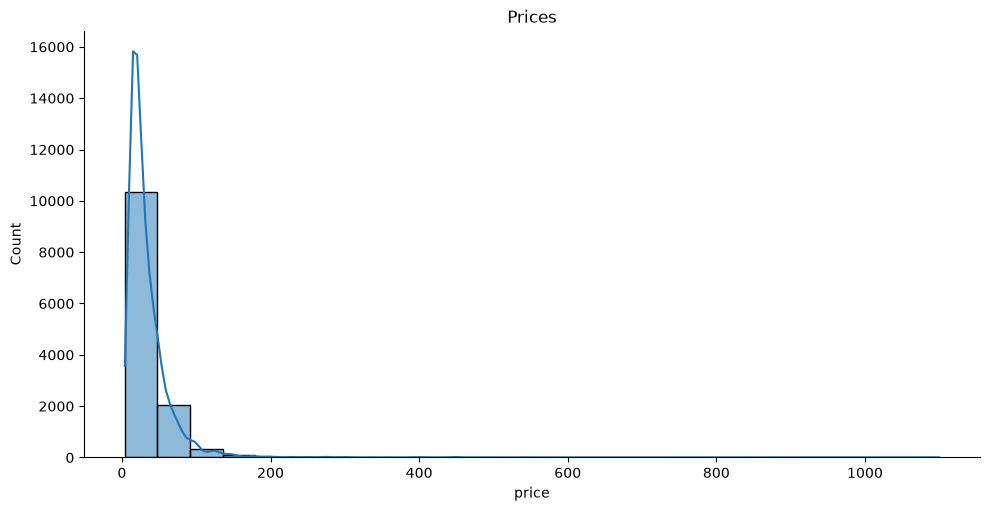

In [19]:
sns.displot(data=pdf, x='price', kde=True, bins=25, height=5, aspect=2).set(title='Prices')

In [20]:
print(pdf['price'].describe())
print()
print(f"mean   = {pdf['price'].mean():.2f}")
print(f"median = {pdf['price'].median():.2f}")
print(f"mean > median -> 右偏（长尾在右侧）")
print(f"skewness = {pdf['price'].skew():.2f}")
print(f"max      = {pdf['price'].max():.2f}")

count    12907.000000
mean        34.086465
std         34.677768
min          4.000000
25%         16.000000
50%         25.000000
75%         40.000000
max       1100.000000
Name: price, dtype: float64

mean   = 34.09
median = 25.00
mean > median -> 右偏（长尾在右侧）
skewness = 8.15
max      = 1100.00


In [21]:
display(data.select(F.log('price')).limit(3))

DataFrame[ln(price): double]

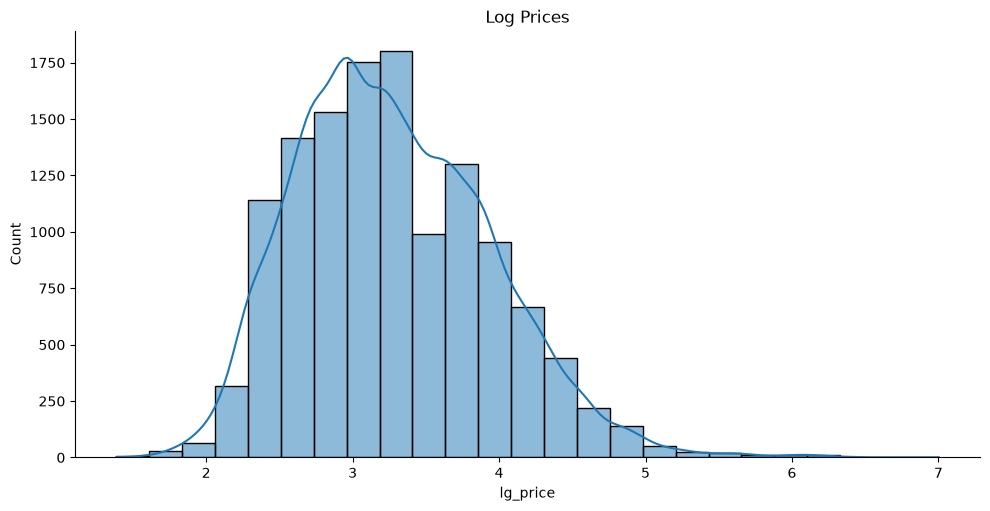

In [22]:
data_lg = sample.withColumn('lg_price', F.log('price'))
pdf_lg = data_lg.toPandas()

sns.displot(data=pdf_lg, x='lg_price', kde=True, bins=25, height=5, aspect=2).set(title='Log Prices')

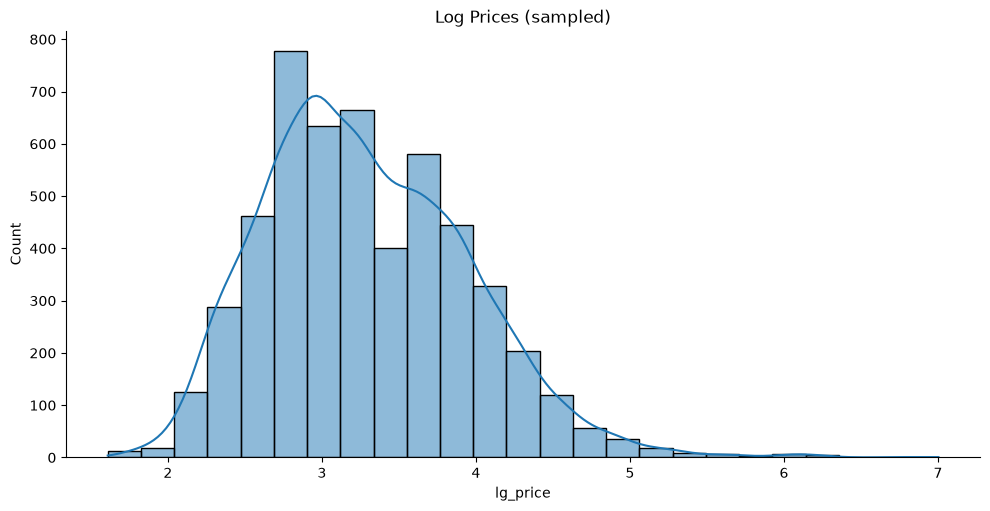

In [23]:
data_lg = sample.withColumn('lg_price', F.log('price'))

fraction = 40 / 100

pdf_lg = data_lg.sample(fraction=fraction, seed=3).toPandas()

sns.displot(data=pdf_lg, x='lg_price', kde=True, bins=25, height=5, aspect=2).set(title='Log Prices (sampled)')

In [24]:
print(f"price     skewness = {pdf['price'].skew():.2f}")
print(f"log(price) skewness = {pdf_lg['lg_price'].skew():.2f}")
print(f"price      max = {pdf['price'].max():.2f}")
print(f"log(price) max = {pdf_lg['lg_price'].max():.2f}")

price     skewness = 8.15
log(price) skewness = 0.59
price      max = 1100.00
log(price) max = 7.00


price < 200 保留 12,841 / 12,907 行 (99.5%)


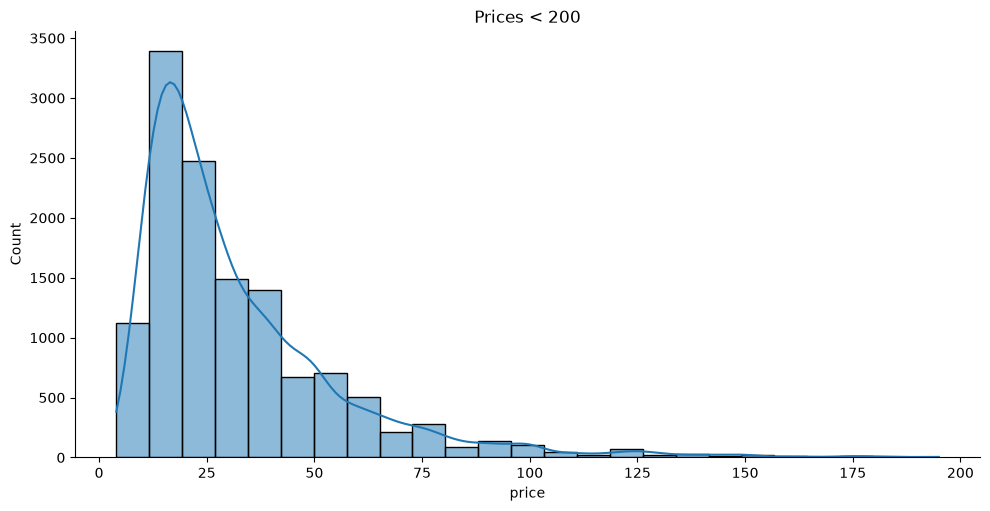

In [25]:
pdf_200 = pdf[pdf['price'] < 200]
print(f"price < 200 保留 {len(pdf_200):,} / {len(pdf):,} 行 ({len(pdf_200) / len(pdf):.1%})")
sns.displot(data=pdf_200, x='price', kde=True, bins=25, height=5, aspect=2).set(title='Prices < 200')

In [26]:
country_pdf = (data.groupby('country')
               .agg(F.count('country').alias('count'),
                    F.avg('price').alias('price'),
                    F.avg('points').alias('points'))
               .orderBy('count', ascending=False)
               .where("count > 1000")
               .toPandas())

print(f"评论数 > 1000 的国家: {len(country_pdf)} 个")
display(country_pdf)

评论数 > 1000 的国家: 14 个


,country,count,price,points
0,US,116381,35.011144,88.166144
1,Italy,35693,38.551004,88.526910
2,France,32557,43.172620,88.675339
3,Spain,14732,27.568966,86.929405
4,Chile,10181,19.970337,86.383558
5,Argentina,9343,22.288451,86.286204
6,Portugal,9050,26.272265,88.251823
7,Australia,7182,32.599137,88.110554
8,Austria,5278,30.969496,89.721296
9,Germany,4465,40.564614,89.195521


评论数最多的 10 个国家: ['US', 'Italy', 'France', 'Spain', 'Chile', 'Argentina', 'Portugal', 'Australia', 'Austria', 'Germany']


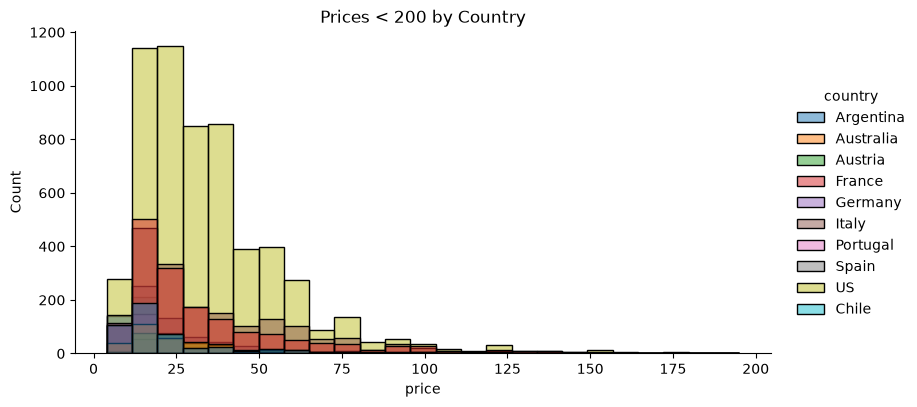

In [27]:
countries = country_pdf['country'].head(10).tolist()
print("评论数最多的 10 个国家:", countries)

plot_data = pdf[pdf['country'].isin(countries) & (pdf['price'] < 200)]
sns.displot(data=plot_data, x='price', bins=25, hue='country', height=4, aspect=2).set(title='Prices < 200 by Country')

countries: ['US', 'Italy', 'France']
varieties: ['Pinot Noir', 'Chardonnay', 'Cabernet Sauvignon']


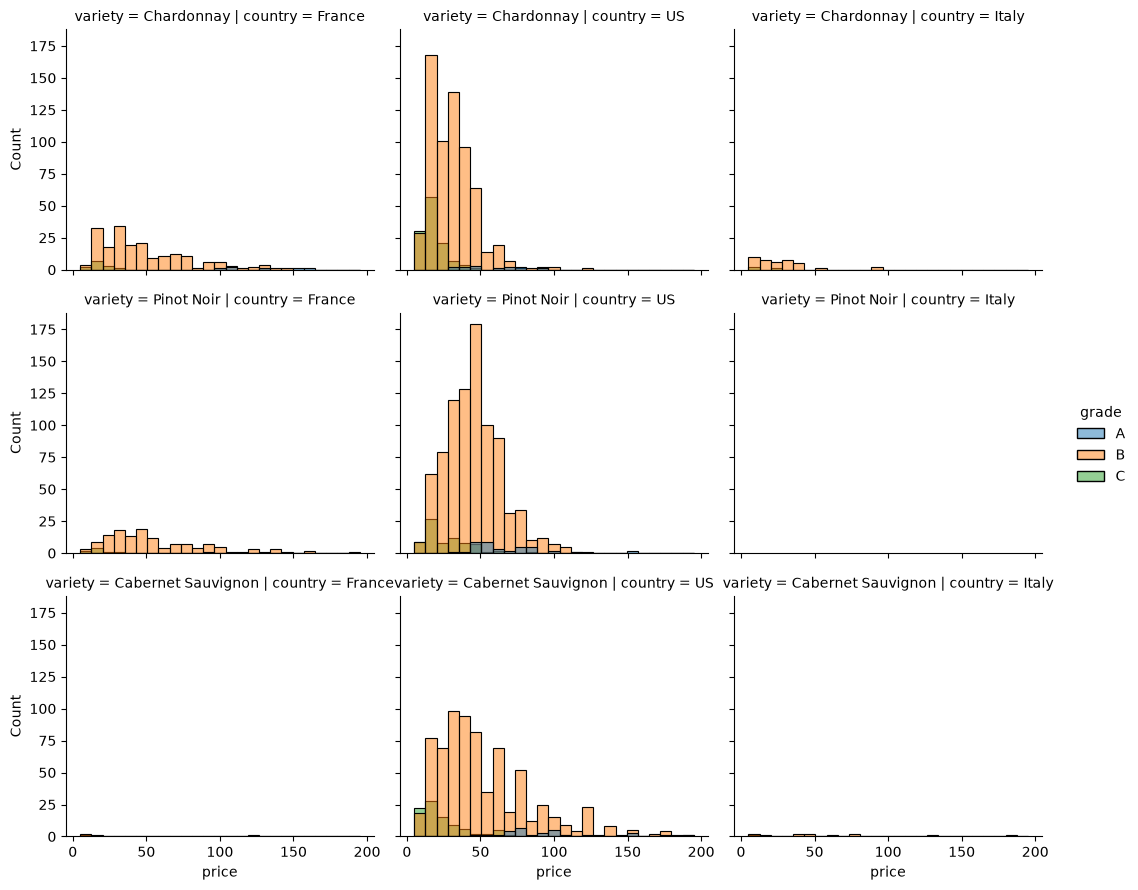

In [28]:
countries = country_pdf['country'].head(3).tolist()

variety_lists = (data.groupby('variety')
                 .agg(F.count('variety').alias('count'))
                 .orderBy('count', ascending=False)
                 .select('variety')
                 .limit(3)
                 .toPandas()
                 .values
                 .tolist())
varieties = [item for sublist in variety_lists for item in sublist]
print("countries:", countries)
print("varieties:", varieties)

sns.displot(
    data=pdf[pdf['country'].isin(countries) & pdf['variety'].isin(varieties) & (pdf['price'] < 200)],
    x='price', bins=25, hue='grade', row='variety', col='country', height=3, aspect=1.2,
)

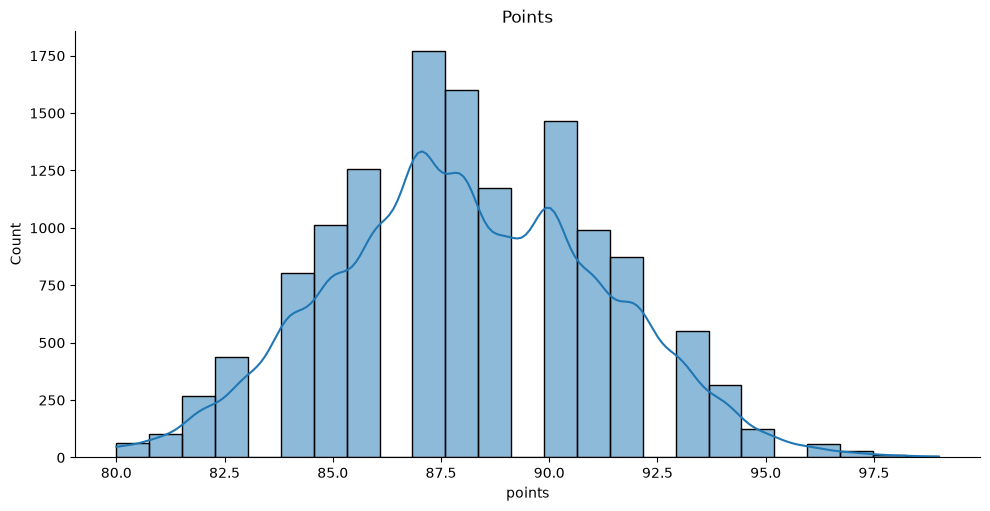

In [29]:
sns.displot(data=pdf, x='points', kde=True, bins=25, height=5, aspect=2).set(title='Points')

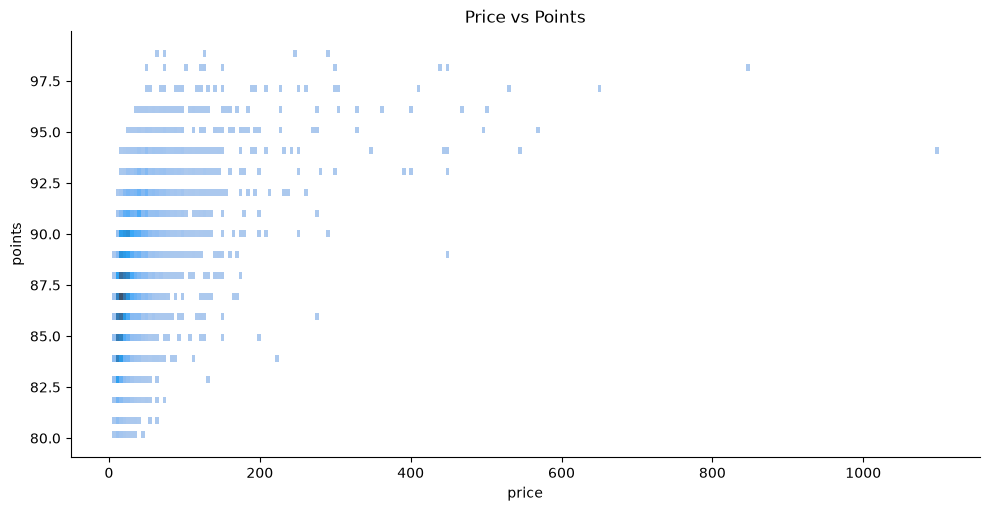

In [30]:
sns.displot(data=pdf, x='price', y='points', height=5, aspect=2).set(title='Price vs Points')

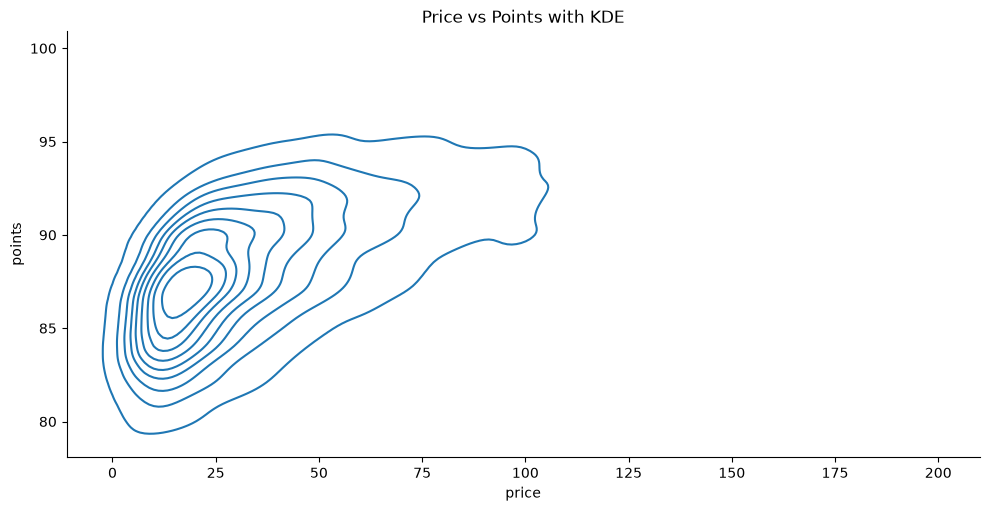

In [31]:
sns.displot(data=pdf[pdf['price'] < 200], x='price', y='points', kind='kde', height=5, aspect=2).set(
    title='Price vs Points with KDE')

<Axes: xlabel='price', ylabel='points'>

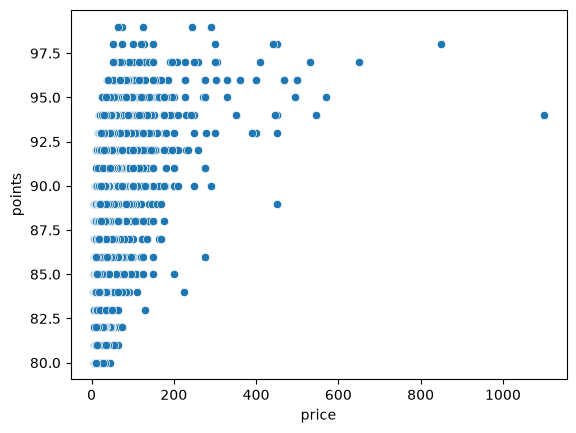

In [32]:
sns.scatterplot(data=pdf, x='price', y='points')

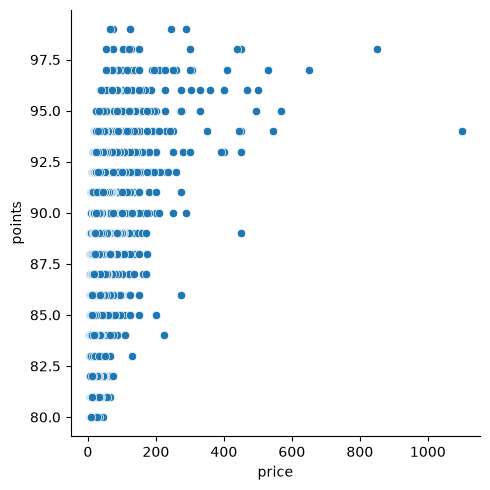

In [33]:
sns.relplot(data=pdf, x='price', y='points', kind='scatter')

参与 pairplot 的数值列: ['points', 'price']


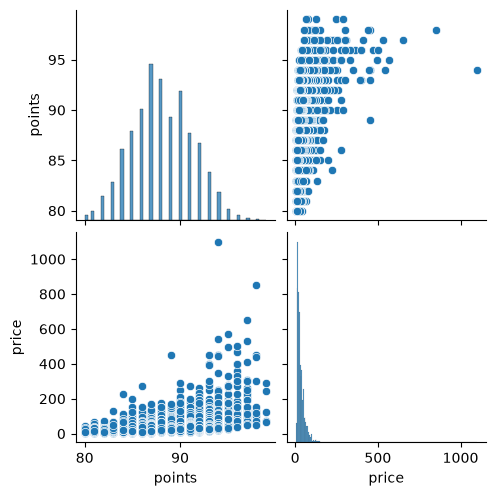

In [34]:
numeric_cols = [c for c in pdf.select_dtypes(include=[np.number]).columns
                if not c.startswith('Unnamed')]
print("参与 pairplot 的数值列:", numeric_cols)
sns.pairplot(pdf[numeric_cols])

<Axes: >

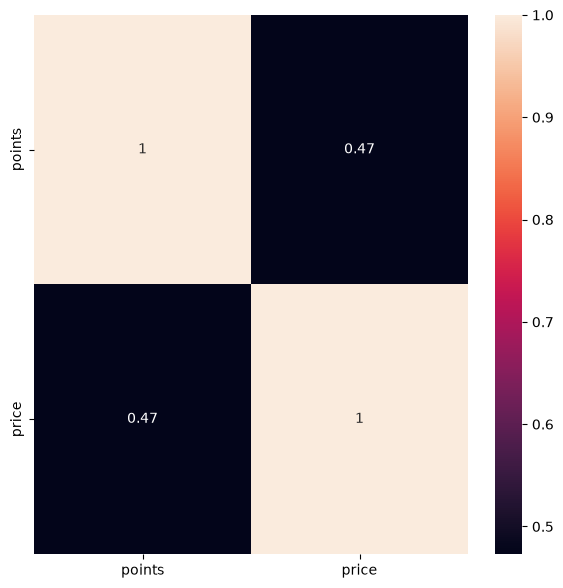

In [35]:
plt.figure(figsize=(7, 7))

sns.heatmap(pdf.corr(numeric_only=True), annot=True)

In [36]:
corr = pdf[['price', 'points']].corr().iloc[0, 1]
print(f"corr(price, points) = {corr:.3f}")
print(f"决定系数 R^2        = {corr ** 2:.3f}")

corr(price, points) = 0.473
决定系数 R^2        = 0.224


In [37]:
plt.figure(figsize=(7, 7))

countries = country_pdf['country'].head(10).tolist()

variety_lists = (data.groupBy('variety')
                 .agg(F.count('variety').alias('count'))
                 .orderBy('count', ascending=False)
                 .select('variety')
                 .limit(10)
                 .toPandas()
                 .values
                 .tolist())
varieties = [item for sublist in variety_lists for item in sublist]

pdfp = pdf[pdf['country'].isin(countries) & pdf['variety'].isin(varieties) & (pdf['price'] < 200)]
points = pdfp.pivot_table(index='variety', columns='country', values='points')
display(points)

country,Argentina,Australia,Austria,Chile,France,Germany,Italy,Portugal,Spain,US
variety,,,,,,,,,,
Bordeaux-style Red Blend,90.153846,87.857143,NaN,89.333333,88.107143,NaN,NaN,NaN,84.000000,89.930233
Cabernet Sauvignon,84.962963,88.622222,88.000000,86.656863,86.000000,87.000000,88.923077,89.000000,83.500000,88.790533
Chardonnay,83.864865,86.977273,90.500000,84.919355,89.092593,91.000000,87.558140,89.666667,84.000000,88.118404
Merlot,83.214286,85.250000,NaN,84.458333,86.250000,NaN,88.869565,NaN,90.000000,86.613475
Pinot Noir,86.318182,86.909091,90.300000,86.473684,89.062500,89.142857,NaN,84.500000,85.666667,89.399797
Red Blend,87.939394,88.500000,89.166667,88.852941,86.850000,NaN,89.000000,86.750000,88.056818,87.600000
Riesling,NaN,87.777778,90.796296,87.500000,89.254902,89.478788,86.333333,NaN,NaN,87.650538
Sauvignon Blanc,84.571429,87.000000,89.500000,85.477612,87.750000,NaN,87.000000,86.000000,83.875000,87.104247
Syrah,84.400000,88.500000,NaN,87.193548,89.153846,NaN,89.727273,89.333333,86.000000,88.769863


<Figure size 700x700 with 0 Axes>

<Axes: xlabel='country', ylabel='variety'>

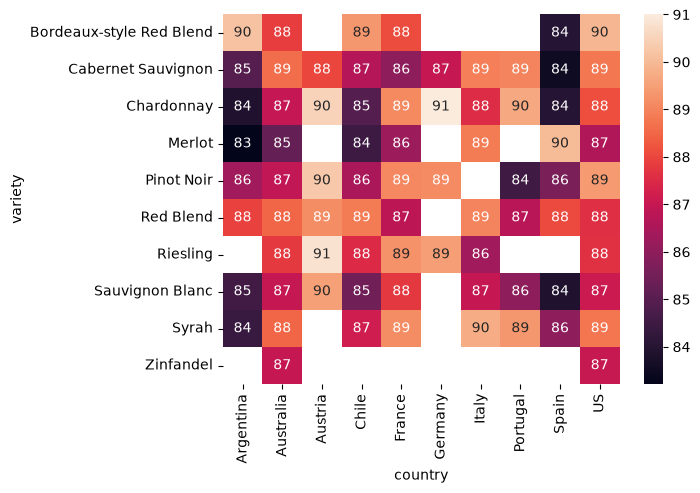

In [38]:
sns.heatmap(points, annot=True)

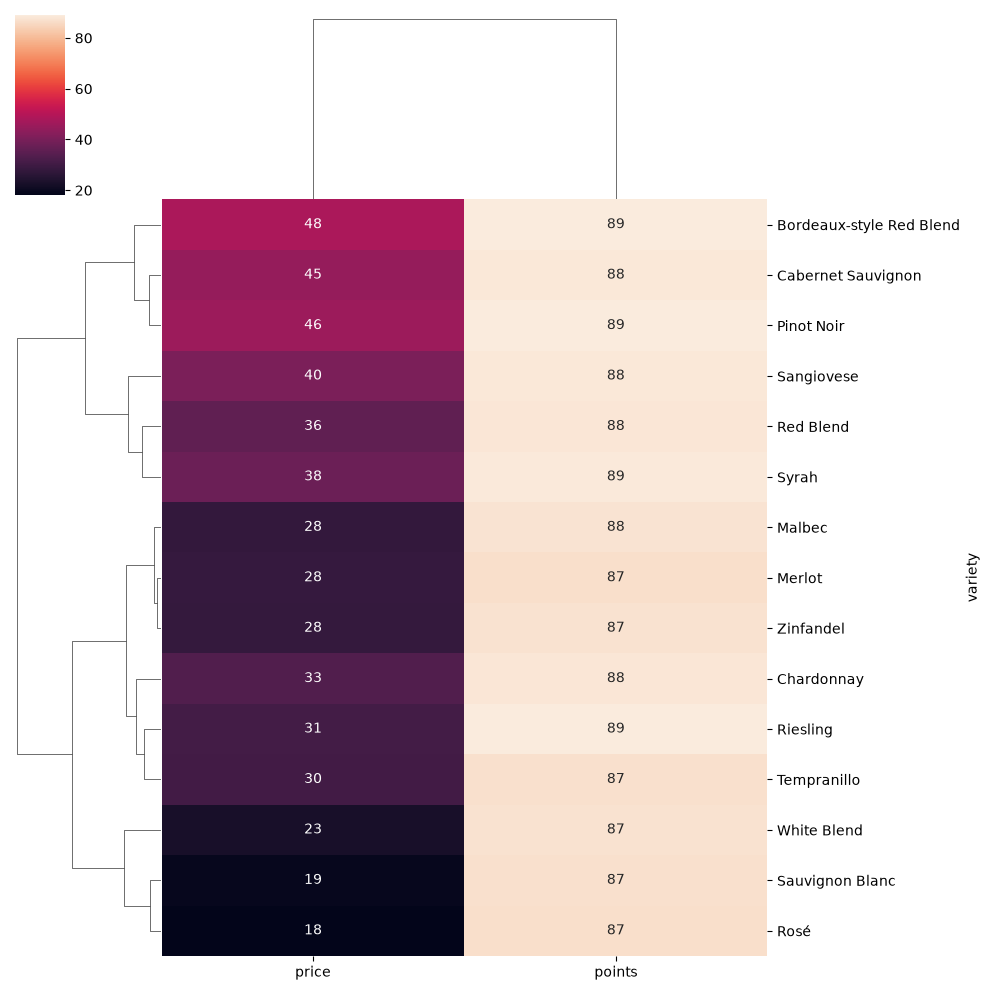

In [39]:
variety_lists = (data.groupBy('variety')
                 .agg(F.count('variety').alias('count'))
                 .orderBy('count', ascending=False)
                 .select('variety')
                 .limit(15)
                 .toPandas()
                 .values
                 .tolist())
varieties = [item for sublist in variety_lists for item in sublist]

vdata = data.groupBy('variety').agg(F.avg('price').alias('price'),
                                    F.avg('points').alias('points')).toPandas()

pdfp = vdata[vdata['variety'].isin(varieties) & (vdata['price'] < 200)]

cluster = pdfp[['variety', 'price', 'points']]
cluster = cluster.set_index('variety', inplace=False)

sns.clustermap(cluster, figsize=(10, 10), annot=True)

[Text(0.5, 1.0, 'Price vs Points with Regression Line (points ~ price)')]

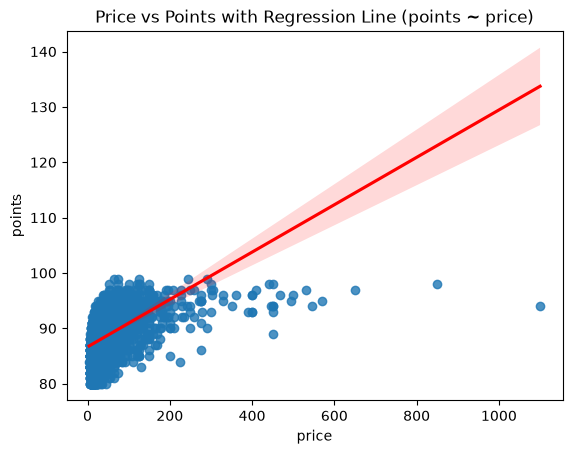

In [40]:
sns.regplot(data=pdf, x='price', y='points', line_kws={'color': 'red'}).set(
    title='Price vs Points with Regression Line (points ~ price)')

In [41]:
countries = country_pdf['country'].head(5).tolist()

n = 3
varieties = (data.groupBy('variety')
             .agg(F.count('variety').alias('count'))
             .orderBy('count', ascending=False)
             .select('variety')
             .limit(n)
             .toPandas()['variety']
             .values
             .tolist())
print("countries:", countries)
print("varieties:", varieties)

pdf_s = pdf[pdf['country'].isin(countries) & pdf['variety'].isin(varieties) & (pdf['price'] < 200)].head(200)

markers = ['.', ',', 'o', 'v', '^', '<', '>', '1', '2', '3', '4', '8', 's', 'p', '*', 'h', 'H', '+', 'x', 'D', 'd', '|',
           '_', 'P', 'X']

sns.set_context('paper', font_scale=1.4)

countries: ['US', 'Italy', 'France', 'Spain', 'Chile']
varieties: ['Pinot Noir', 'Chardonnay', 'Cabernet Sauvignon']


C:\Users\Lenovo\.conda\envs\dbconnect\Lib\site-packages\seaborn\regression.py:411: UserWarning: The pixel maker ',' is not supported on scatter(); using a finite-sized square instead, which is not necessarily 1 pixel in size. Use the square marker 's' instead to suppress this warning.
  ax.scatter(x, y, **kws)


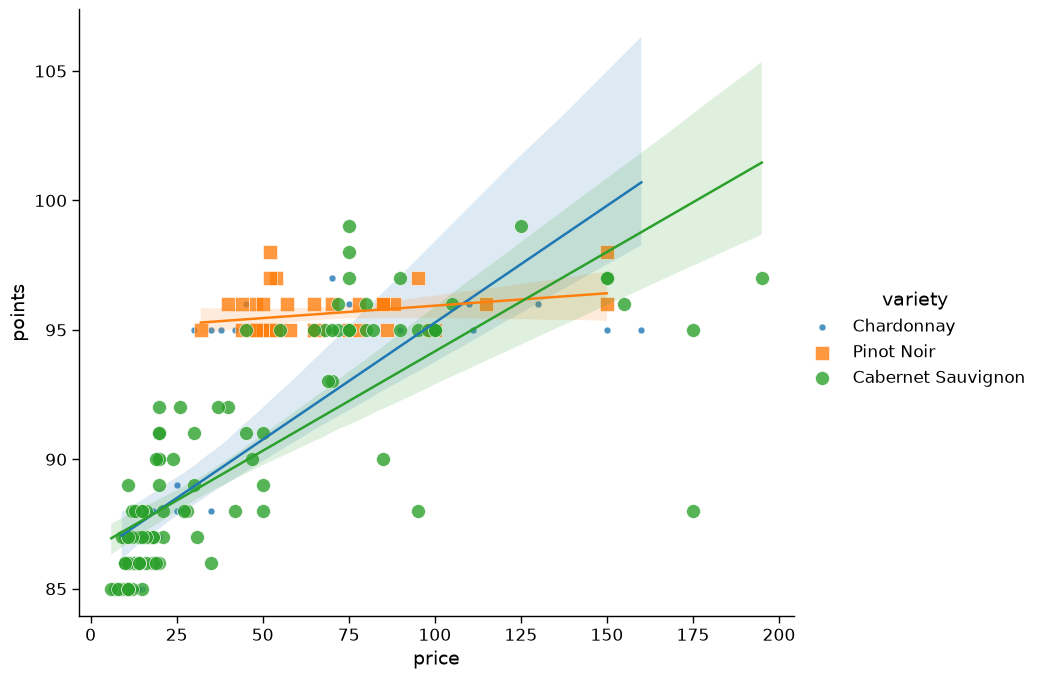

In [42]:
sns.lmplot(
    data=pdf_s,
    x='price',
    y='points',
    hue='variety',
    markers=markers[:n],
    scatter_kws={'s': 100, 'linewidths': 0.5, 'edgecolor': 'w'},
    height=7,
    aspect=1.2,
)

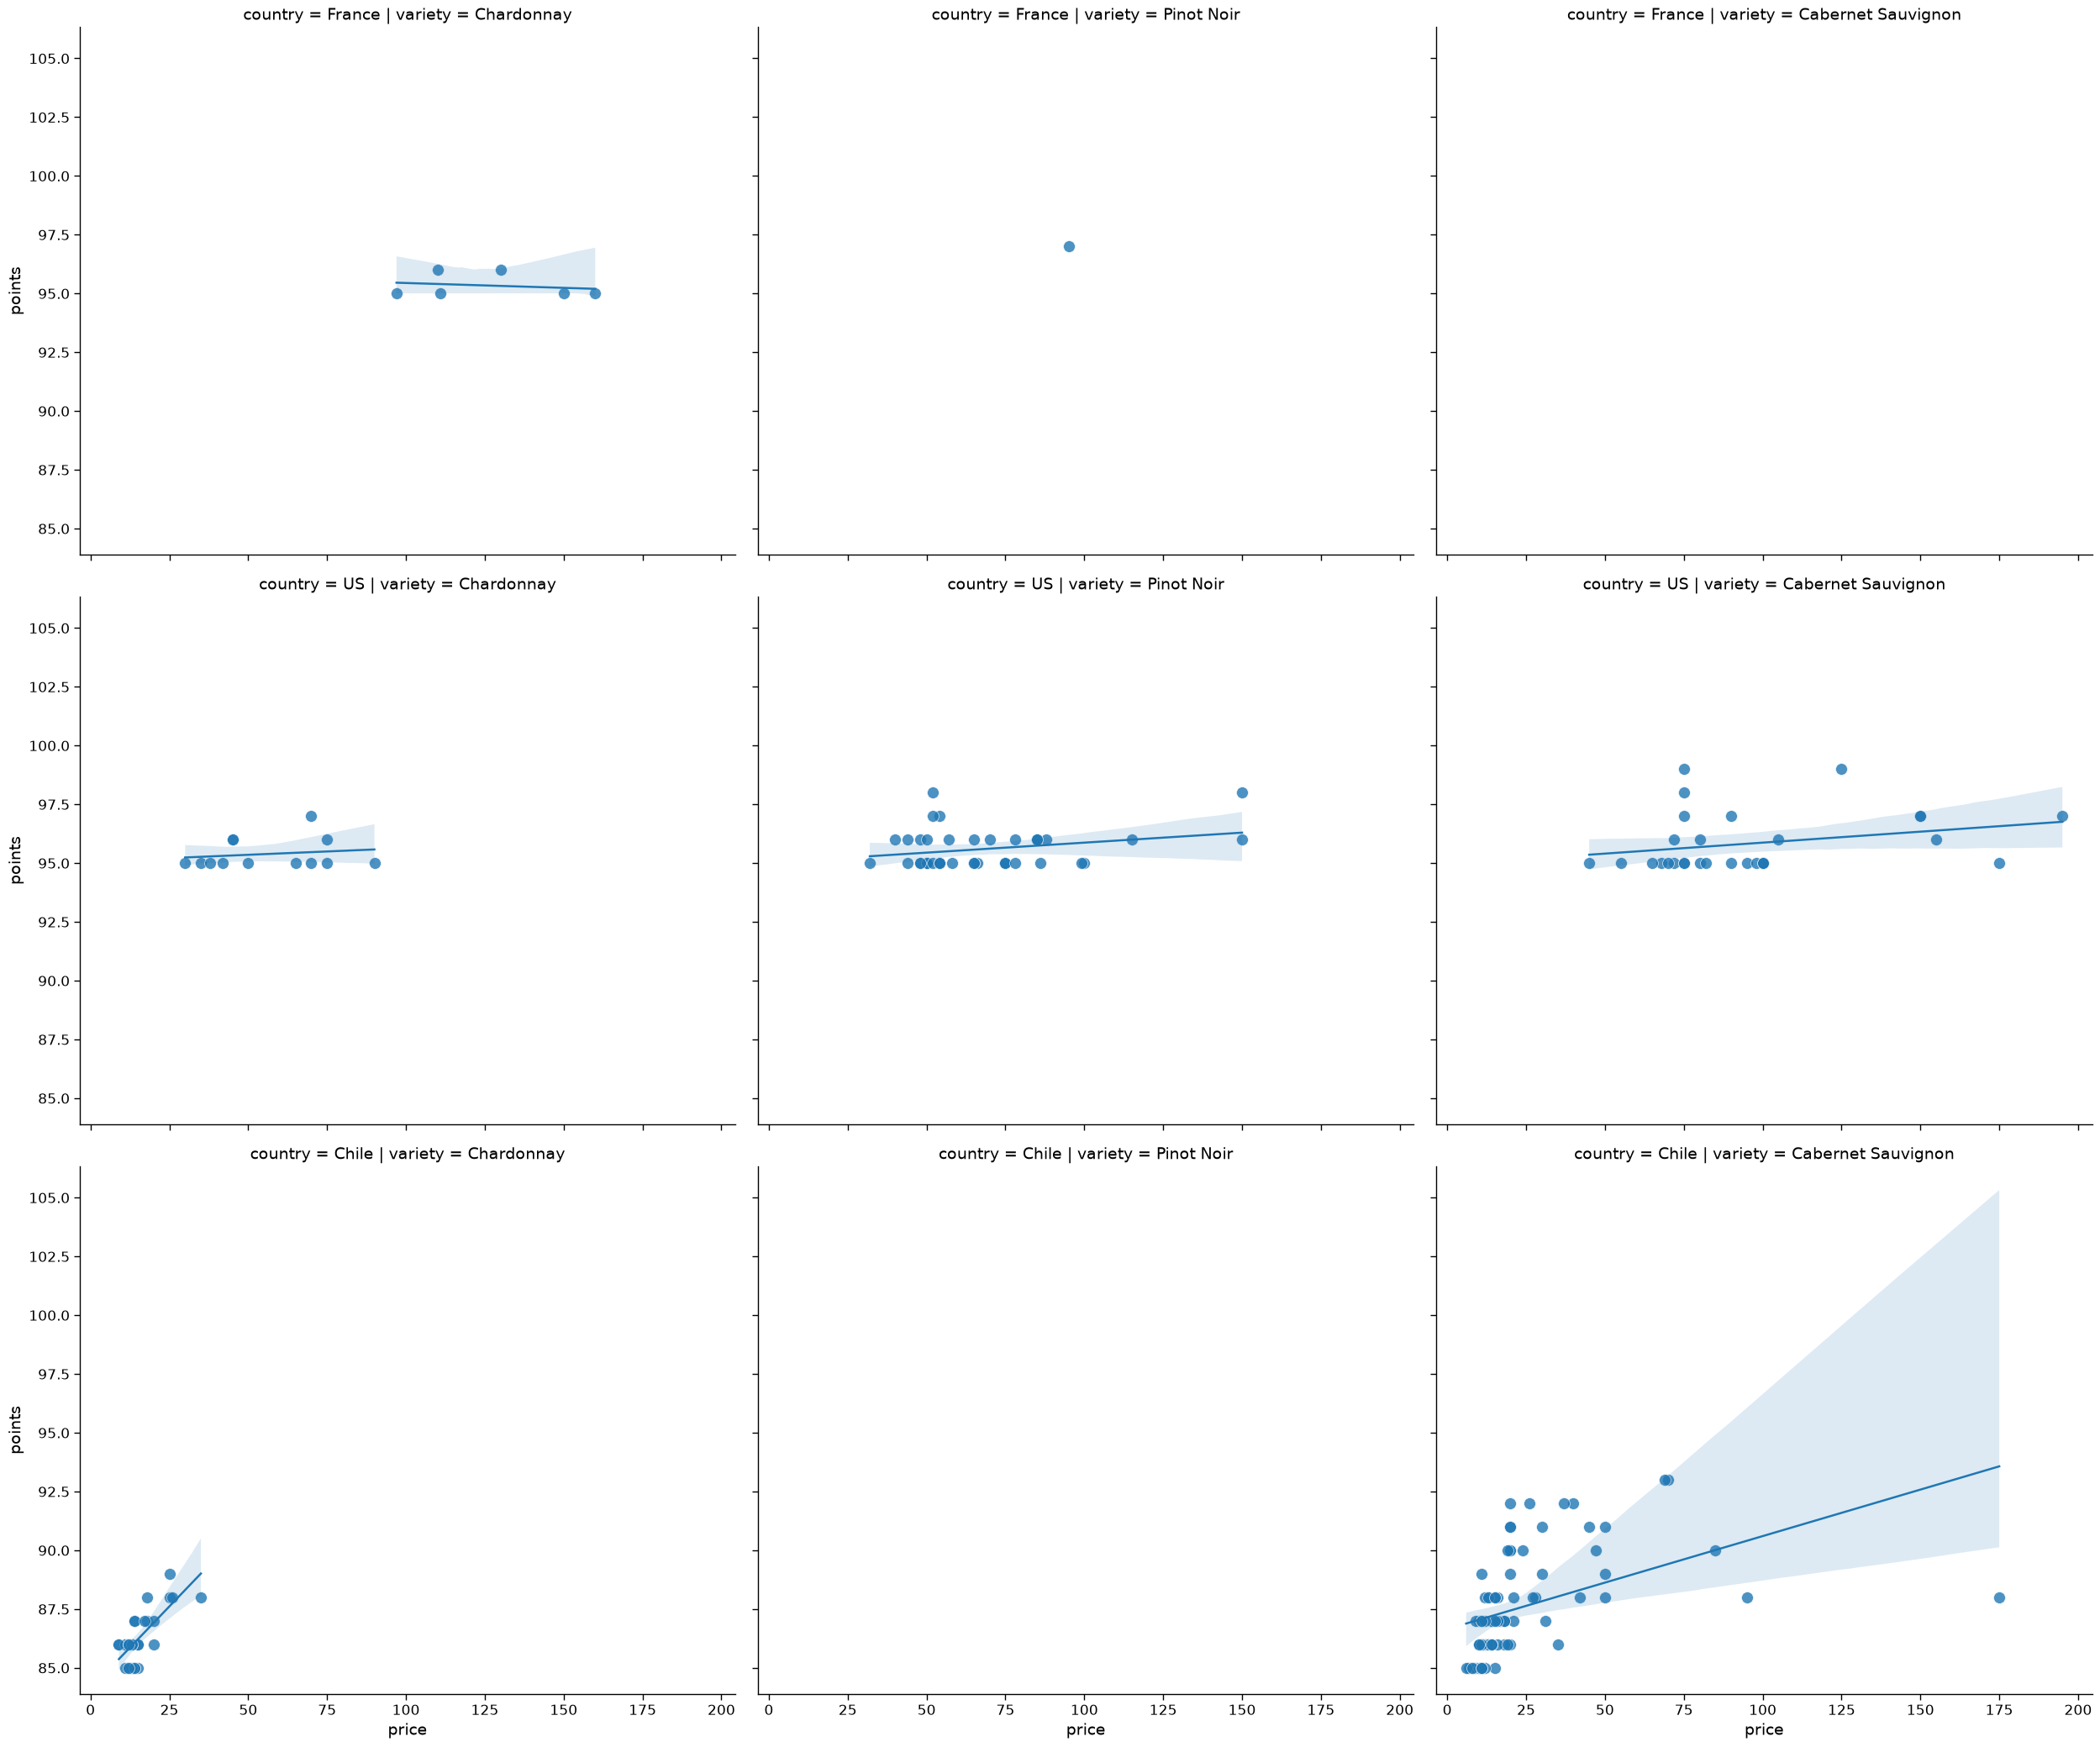

In [43]:
sns.lmplot(
    data=pdf_s,
    x='price',
    y='points',
    col='variety',
    row='country',
    scatter_kws={
        's': 100,
        'linewidths': 0.5,
        'edgecolor': 'w',
    },
    height=7,
    aspect=1.2,
)

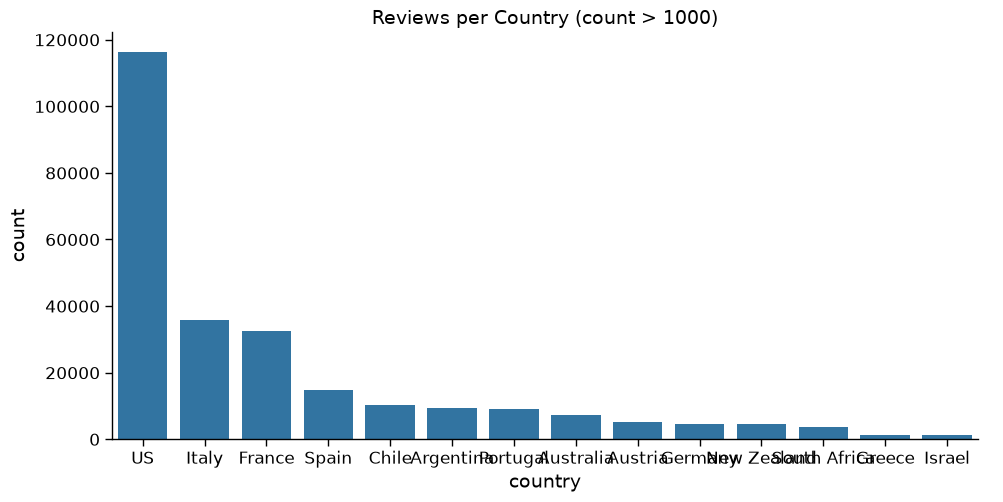

In [44]:
country_pdf = (data.groupby('country')
               .agg(F.count('country').alias('count'),
                    F.avg('price').alias('price'),
                    F.avg('points').alias('points'))
               .orderBy('count', ascending=False)
               .where("count > 1000")
               .toPandas())

sns.catplot(data=country_pdf, x='country', y='count', kind='bar', height=5, aspect=2).set(
    title='Reviews per Country (count > 1000)')

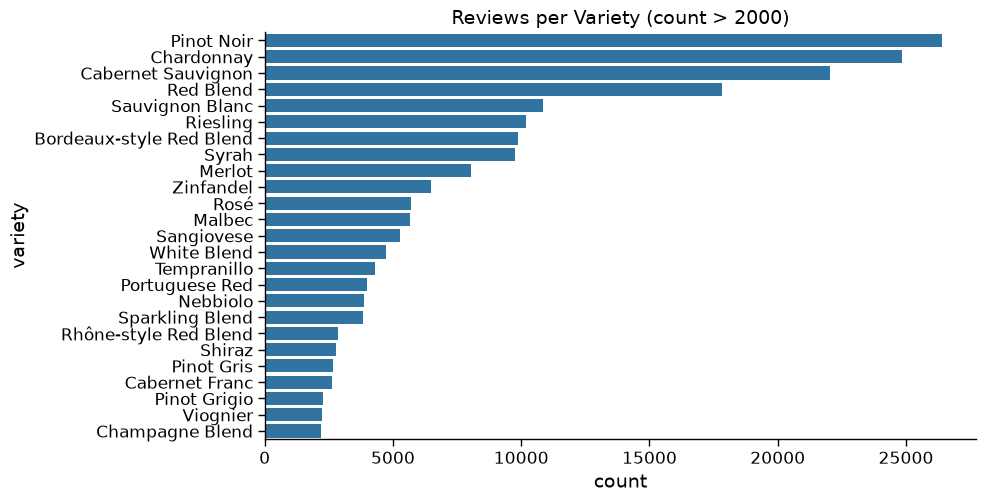

In [45]:
variety_pdf = (data.groupby('variety')
               .agg(F.count('variety').alias('count'),
                    F.avg('price').alias('price'),
                    F.avg('points').alias('points'))
               .orderBy('count', ascending=False)
               .where("count > 2000")
               .toPandas())

sns.catplot(data=variety_pdf, x='count', y='variety', kind='bar', height=5, aspect=2, orient='h').set(
    title='Reviews per Variety (count > 2000)')

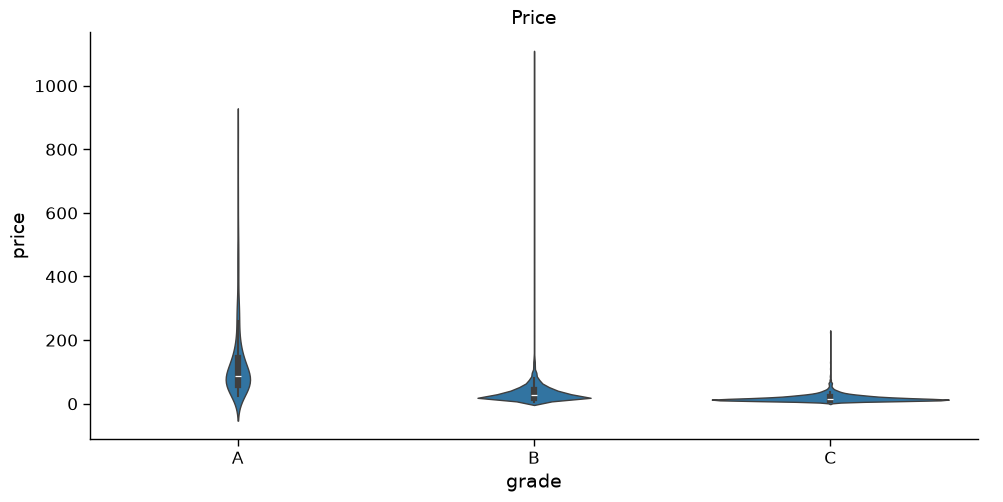

In [46]:
sns.catplot(data=pdf, x='grade', y='price', kind='violin', height=5, aspect=2).set(title='Price')

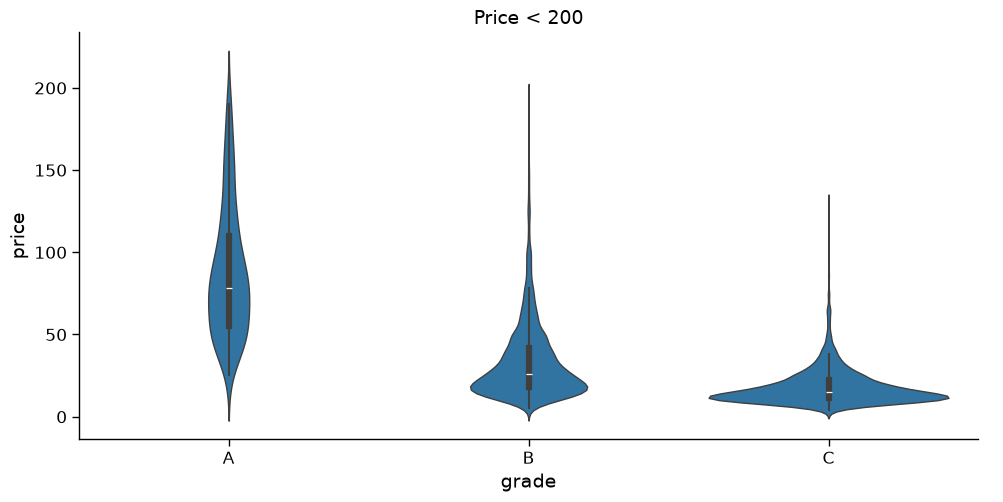

In [47]:
sns.catplot(data=pdf[pdf['price'] < 200], x='grade', y='price', kind='violin', height=5, aspect=2).set(
    title='Price < 200')

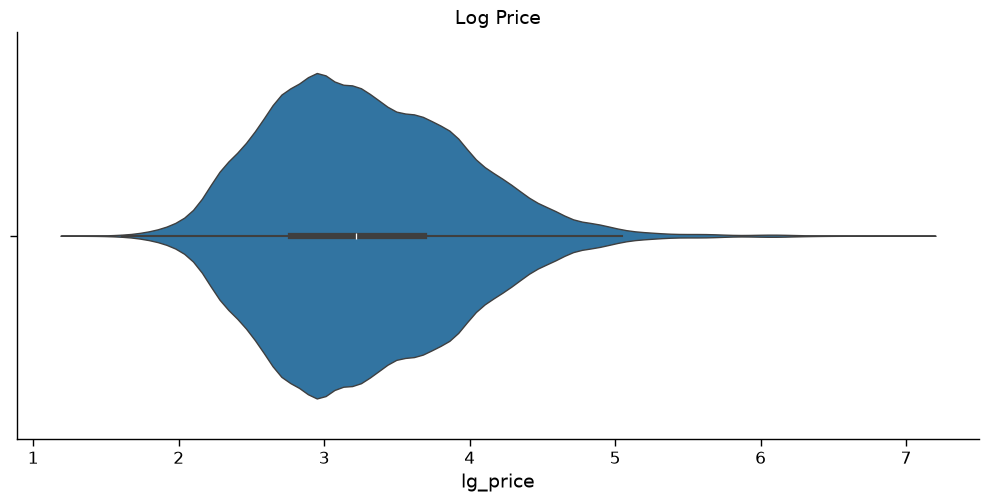

In [48]:
data_lg = sample.withColumn('lg_price', F.log('price'))
pdf_lg = data_lg.toPandas()
sns.catplot(data=pdf_lg, x='lg_price', kind='violin', height=5, aspect=2).set(title='Log Price')

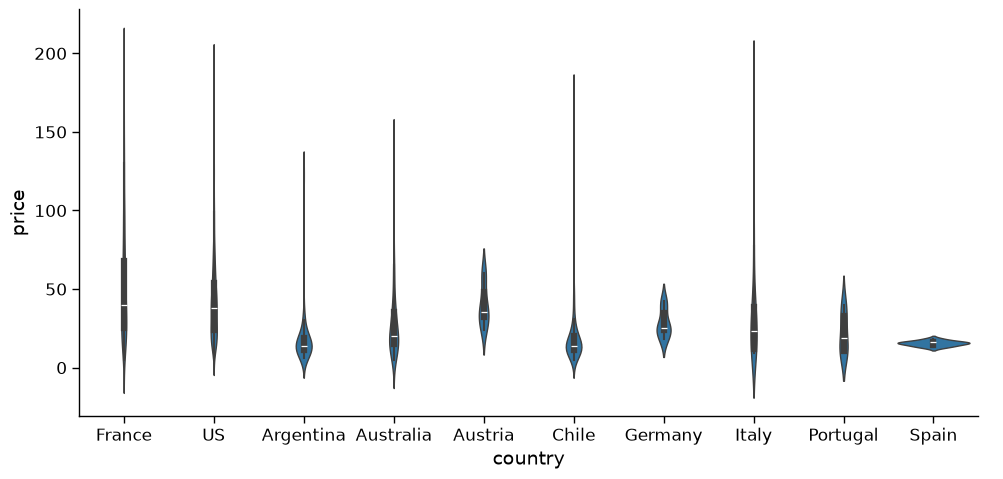

In [49]:
countries = country_pdf['country'].head(10).tolist()

variety_lists = (data.groupBy('variety')
                 .agg(F.count('variety').alias('count'))
                 .orderBy('count', ascending=False)
                 .select('variety')
                 .limit(3)
                 .toPandas()
                 .values
                 .tolist())
varieties = [item for sublist in variety_lists for item in sublist]

sns.catplot(
    data=pdf[pdf['country'].isin(countries) & pdf['variety'].isin(varieties) & (pdf['price'] < 200)],
    x='country',
    y='price',
    kind='violin',
    height=5,
    aspect=2,
)

In [50]:
countries = country_pdf['country'].head(10).tolist()

varieties = (data.groupBy('variety')
             .agg(F.count('variety').alias('count'))
             .orderBy('count', ascending=False)
             .select('variety')
             .limit(4)
             .toPandas()['variety']
             .tolist())

filtered_pdf = pdf[
    pdf['country'].isin(countries)
    & pdf['variety'].isin(varieties)
    & (pdf['price'] < 200)
]
print(f"filtered_pdf: {filtered_pdf.shape}")

filtered_pdf: (4287, 10)


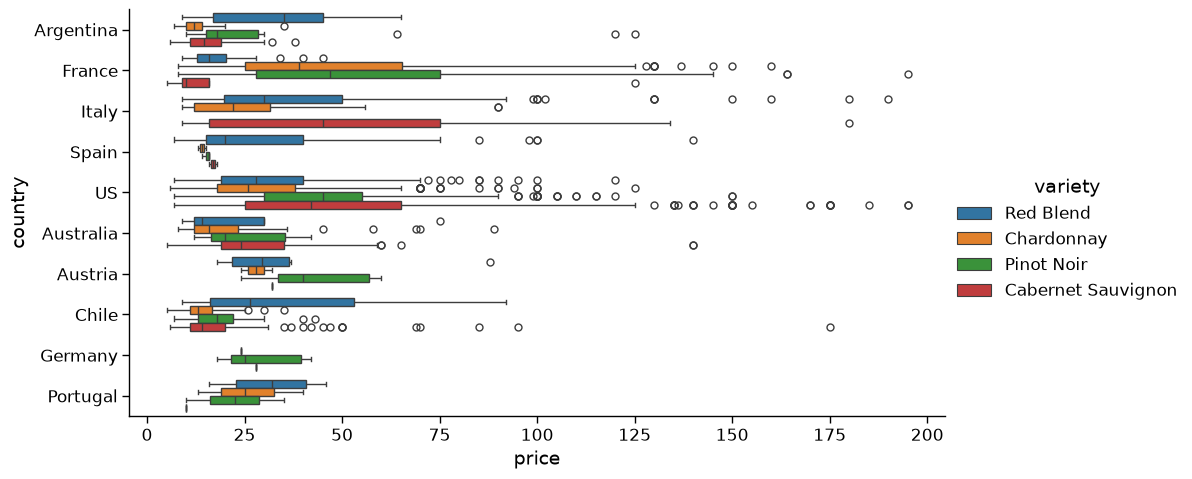

In [51]:
sns.catplot(
    data=filtered_pdf,
    x='price',
    y='country',
    hue='variety',
    kind='box',
    height=5,
    aspect=2,
)

In [52]:
countries = country_pdf['country'].head(10).tolist()

varieties = (data.groupBy('variety')
             .agg(F.count('variety').alias('count'))
             .orderBy('count', ascending=False)
             .select('variety')
             .limit(3)
             .toPandas()['variety']
             .tolist())

filtered_pdf = pdf[
    pdf['country'].isin(countries)
    & pdf['variety'].isin(varieties)
    & (pdf['price'] < 200)
]
print(f"filtered_pdf: {filtered_pdf.shape}")

filtered_pdf: (3477, 10)


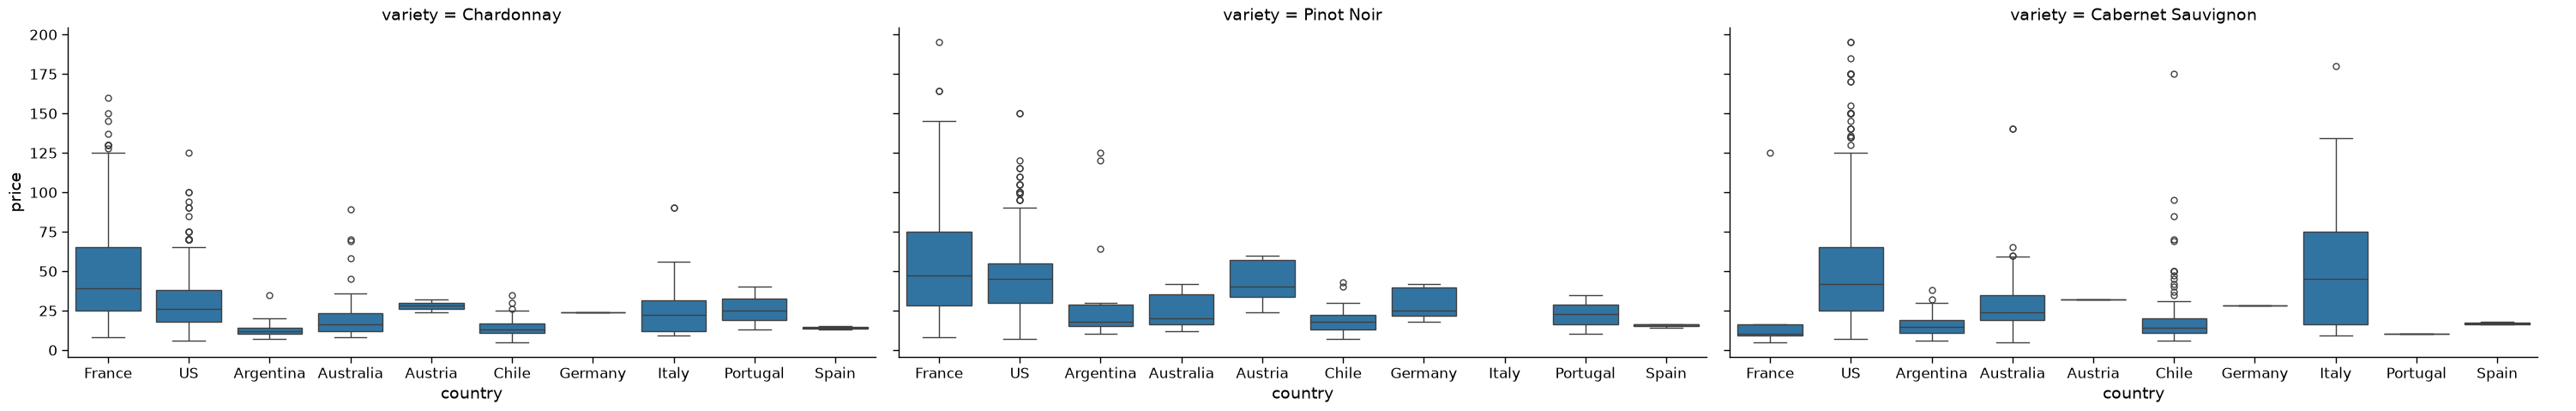

In [53]:
sns.catplot(
    data=filtered_pdf,
    x='country',
    y='price',
    col='variety',
    kind='box',
    height=5,
    aspect=2,
)

In [54]:
summary_pdf = (data.groupBy('grade')
               .agg(F.count('grade').alias('count'),
                    F.avg('price').alias('avg_price'),
                    F.expr('percentile_approx(price, 0.5)').alias('median_price'),
                    F.avg('points').alias('avg_points'))
               .orderBy('grade')
               .toPandas())
display(summary_pdf)

,grade,count,avg_price,median_price,avg_points
0,A,4724,136.258467,86.0,95.657282
1,B,219338,34.370004,26.0,88.699674
2,C,34032,18.775594,15.0,83.070199
